<a href="https://colab.research.google.com/github/wingchicken1225-del/Probabilidad/blob/main/Unidad6/Proyecto%20Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Probabilidad y Estadistica**

## Unidad 6

## **Proyecto Final**

Docente: Dr. Jose Gabriel Rodriguez Rivas

Equipo: Jesus Antonio Soto

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [18]:
columnas = ["FECHA_INGRESO", "ENTIDAD_NAC", "SEXO", "TIPO_PACIENTE", "EDAD", "EMBARAZO", "INDIGENA",
            "RESULTADO_ANTIGENO", "DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
            "RENAL_CRONICA", "CARDIOVASCULAR", "TABAQUISMO"]

estados = ["Aguascalientes", "Baja California", "Baja California Sur", "Campeche", "Chiapas", "Chihuahua",
           "Ciudad De México", "Coahuila De Zaragoza", "Colima", "Durango", "Guanajuato", "Guerrero",
           "Hidalgo", "Jalisco", "Michoacán De Ocampo", "Morelos", "México", "Nayarit", "Nuevo León",
           "Oaxaca", "Puebla", "Querétaro", "Quintana Roo", "San Luis Potosí", "Sinaloa", "Sonora",
           "Tabasco", "Tamaulipas", "Tlaxcala", "Veracruz", "Yucatán", "Zacatecas"]

si_no = pd.CategoricalDtype(["Si", "No", "Se ignora"])
tipos = {"ENTIDAD_NAC": pd.CategoricalDtype(estados + ["99"]),
         "SEXO": pd.CategoricalDtype(["Femenino", "Masculino"]),
         "TIPO_PACIENTE": pd.CategoricalDtype(["Ambulatorio", "Hospitalizado"]),
         "EMBARAZO": pd.CategoricalDtype(["Si", "No", "Se ignora", "No aplica", "No especificado"]),
         "INDIGENA": pd.CategoricalDtype(["Si", "No", "No especificado"]),
         "RESULTADO_ANTIGENO": pd.CategoricalDtype(["Positivo", "Negativo", "Pendiente"]),
         "EDAD": "int16",
         "DIABETES": si_no, "HIPERTENSION": si_no, "OBESIDAD": si_no, "EPOC": si_no,
         "ASMA": si_no, "RENAL_CRONICA": si_no, "CARDIOVASCULAR": si_no, "TABAQUISMO": si_no}

In [19]:
ruta = "/content/sample_data/covid2020-2021-codificado.csv"

df = pd.read_csv(ruta, usecols=columnas, dtype=tipos, parse_dates=["FECHA_INGRESO"])
print(f"Total de registros: {len(df):,}")
print(df.head())

Total de registros: 12,634,194
        SEXO       ENTIDAD_NAC TIPO_PACIENTE FECHA_INGRESO  EDAD   EMBARAZO  \
0   Femenino   San Luis Potosí   Ambulatorio    2020-12-06    55         No   
1  Masculino   San Luis Potosí   Ambulatorio    2020-02-20    59  No aplica   
2   Femenino           Jalisco   Ambulatorio    2020-04-22    42         No   
3  Masculino         Chihuahua   Ambulatorio    2020-07-28    35  No aplica   
4  Masculino  Ciudad De México   Ambulatorio    2020-08-18    51  No aplica   

  INDIGENA DIABETES EPOC ASMA HIPERTENSION CARDIOVASCULAR OBESIDAD  \
0       No       Si   No   No           No             No       No   
1       No       No   No   No           No             No       No   
2       No       No   No   Si           No             No       No   
3       No       No   No   No           No             No       No   
4       No       No   No   No           Si             No       No   

  RENAL_CRONICA TABAQUISMO RESULTADO_ANTIGENO  
0            No         N

In [20]:
positivos2 = (df["RESULTADO_ANTIGENO"] == "Positivo").sum()
negativos2 = (df["RESULTADO_ANTIGENO"] == "Negativo").sum()
pendientes2 = (df["RESULTADO_ANTIGENO"] == "Pendiente").sum()

print(f"Casos positivos: {positivos2:,}")
print(f"Casos negativos: {negativos2:,}")
print(f"Casos pendientes de resultado: {pendientes2:,}")
print()

Casos positivos: 1,774,708
Casos negativos: 5,853,547
Casos pendientes de resultado: 5,005,939



In [21]:
hospitalizados2 = (df["TIPO_PACIENTE"] == "Hospitalizado").sum()
ambulatorios2 = (df["TIPO_PACIENTE"] == "Ambulatorio").sum()

print(f"Pacientes hospitalizados: {hospitalizados2:,}")
print(f"Pacientes ambulatorios: {ambulatorios2:,}")
print()

Pacientes hospitalizados: 1,090,891
Pacientes ambulatorios: 11,543,303



In [22]:
embarazadas2 = (df["EMBARAZO"] == "Si").sum()
print(f"Pacientes embarazadas: {embarazadas2:,}")
print()

Pacientes embarazadas: 122,583



In [23]:
indigenas2 = (df["INDIGENA"] == "Si").sum()
print(f"Pacientes indigenas: {indigenas2:,}")

Pacientes indigenas: 35,240


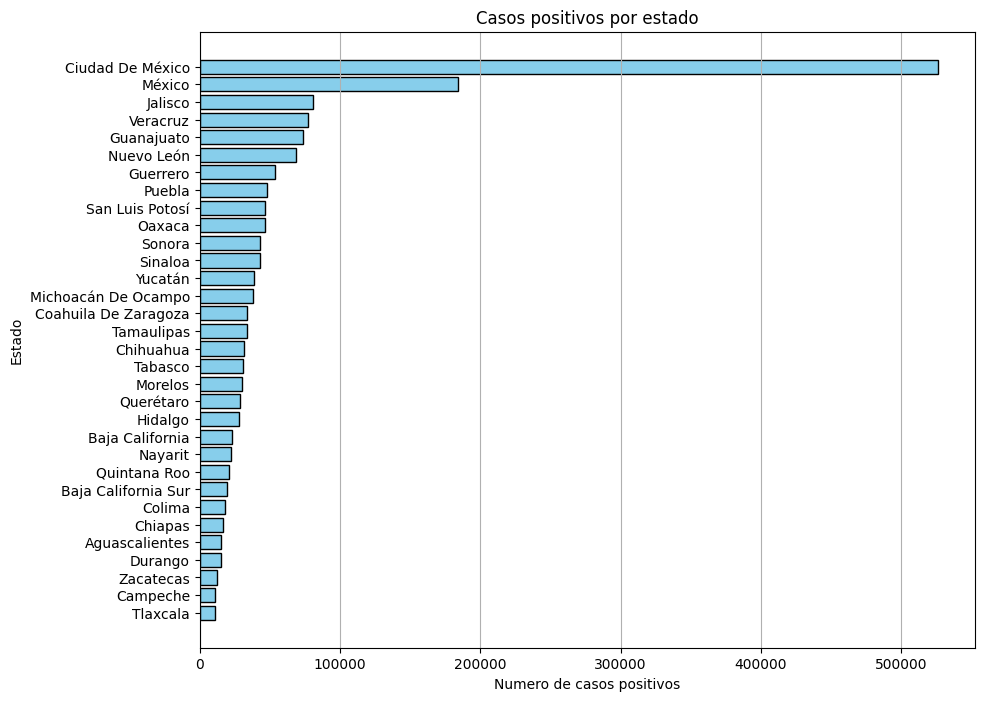

In [24]:
df_pos = df[df["RESULTADO_ANTIGENO"] == "Positivo"]

casos_estado3 = df_pos["ENTIDAD_NAC"].value_counts().drop("99").sort_values()

plt.figure(figsize=(10, 8))
plt.barh(casos_estado3.index.astype(str), casos_estado3.values, color='skyblue', edgecolor='black')
plt.title("Casos positivos por estado")
plt.xlabel("Numero de casos positivos")
plt.ylabel("Estado")
plt.grid(True, axis='x')
plt.show()

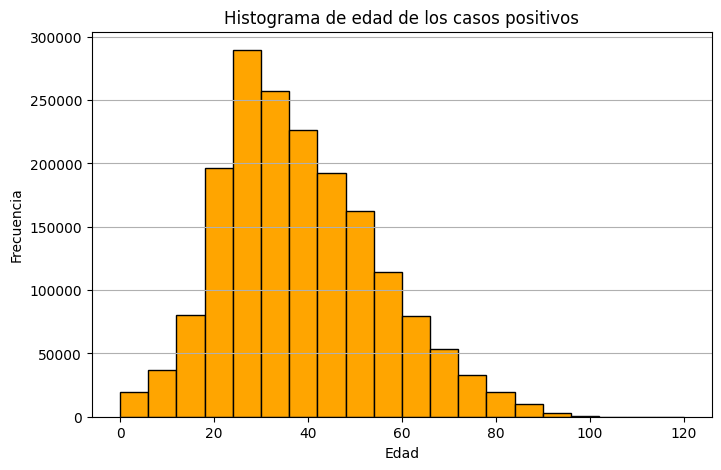

In [25]:
plt.figure(figsize=(8, 5))
plt.hist(df_pos["EDAD"], bins=20, range=(0, 120), color='orange', edgecolor='black')
plt.title("Histograma de edad de los casos positivos")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")
plt.grid(True, axis='y')
plt.show()

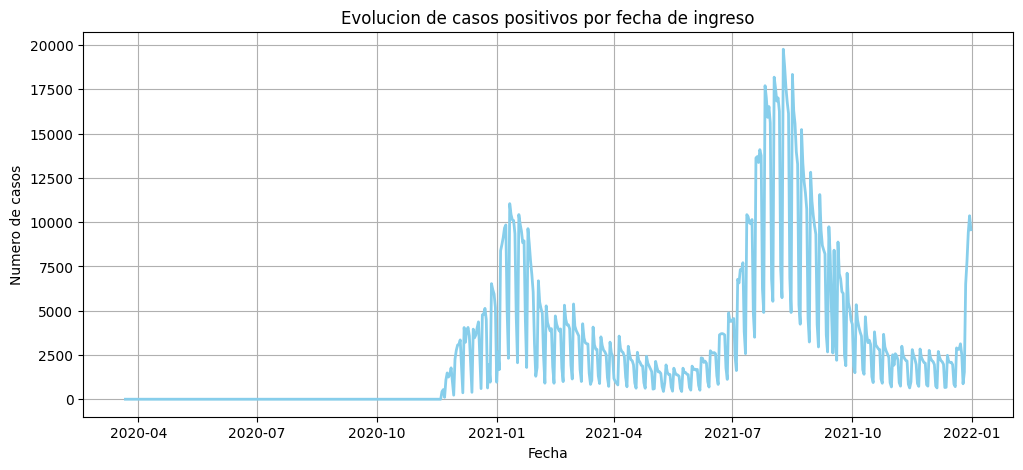

In [26]:
casos_fecha3 = df_pos.groupby("FECHA_INGRESO").size()

plt.figure(figsize=(12, 5))
plt.plot(casos_fecha3.index, casos_fecha3.values, color='skyblue', linewidth=2)
plt.title("Evolucion de casos positivos por fecha de ingreso")
plt.xlabel("Fecha")
plt.ylabel("Numero de casos")
plt.grid(True)
plt.show()

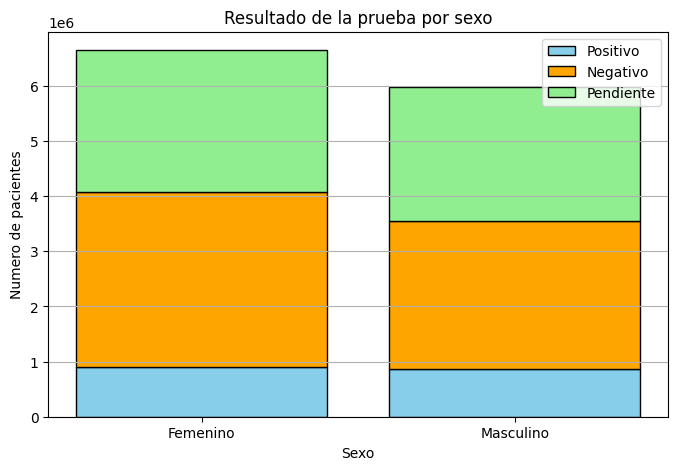

In [27]:
tabla3 = pd.crosstab(df["SEXO"], df["RESULTADO_ANTIGENO"])
sexos3 = list(tabla3.index)

plt.figure(figsize=(8, 5))
plt.bar(sexos3, tabla3["Positivo"], color='skyblue', edgecolor='black', label="Positivo")
plt.bar(sexos3, tabla3["Negativo"], bottom=tabla3["Positivo"], color='orange', edgecolor='black', label="Negativo")
plt.bar(sexos3, tabla3["Pendiente"], bottom=tabla3["Positivo"] + tabla3["Negativo"], color='lightgreen', edgecolor='black', label="Pendiente")
plt.title("Resultado de la prueba por sexo")
plt.xlabel("Sexo")
plt.ylabel("Numero de pacientes")
plt.legend()
plt.grid(True, axis='y')
plt.show()

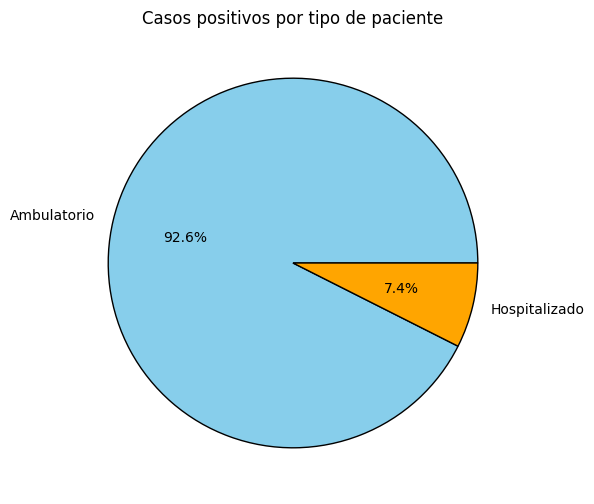

In [28]:
tipo3 = df_pos["TIPO_PACIENTE"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(tipo3.values, labels=tipo3.index, autopct='%1.1f%%', colors=['skyblue', 'orange'],
        wedgeprops=dict(edgecolor='black'))
plt.title("Casos positivos por tipo de paciente")
plt.show()

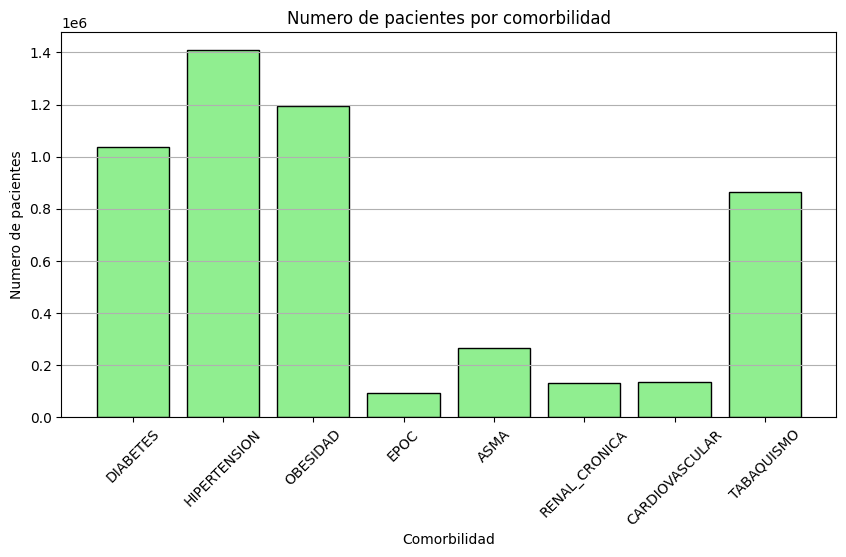

In [29]:
comorbilidades = ["DIABETES", "HIPERTENSION", "OBESIDAD", "EPOC", "ASMA",
                  "RENAL_CRONICA", "CARDIOVASCULAR", "TABAQUISMO"]
totales3 = (df[comorbilidades] == "Si").sum()

plt.figure(figsize=(10, 5))
plt.bar(comorbilidades, totales3.values, color='lightgreen', edgecolor='black')
plt.title("Numero de pacientes por comorbilidad")
plt.xlabel("Comorbilidad")
plt.ylabel("Numero de pacientes")
plt.xticks(rotation=45)
plt.grid(True, axis='y')
plt.show()

In [30]:
total4 = len(df)
print(f"Total general de casos: {total4:,}")
print()

print("Total de pacientes con cada comorbilidad:")
print(totales3.to_string())
print()

prob_simple4 = totales3 / total4
print("Probabilidad simple de cada comorbilidad:")
for nombre4, valor4 in prob_simple4.items():
    print(f"P({nombre4}) = {valor4:.4f}")

Total general de casos: 12,634,194

Total de pacientes con cada comorbilidad:
DIABETES          1038459
HIPERTENSION      1407779
OBESIDAD          1193021
EPOC                92446
ASMA               263855
RENAL_CRONICA      129874
CARDIOVASCULAR     134410
TABAQUISMO         865162

Probabilidad simple de cada comorbilidad:
P(DIABETES) = 0.0822
P(HIPERTENSION) = 0.1114
P(OBESIDAD) = 0.0944
P(EPOC) = 0.0073
P(ASMA) = 0.0209
P(RENAL_CRONICA) = 0.0103
P(CARDIOVASCULAR) = 0.0106
P(TABAQUISMO) = 0.0685


In [31]:
prob_estado4 = (df[comorbilidades] == "Si").groupby(df["ENTIDAD_NAC"], observed=True).mean().drop("99")

print("Probabilidad condicional de cada comorbilidad por entidad federativa:")
print(prob_estado4.round(4).to_string())

Probabilidad condicional de cada comorbilidad por entidad federativa:
                      DIABETES  HIPERTENSION  OBESIDAD    EPOC    ASMA  RENAL_CRONICA  CARDIOVASCULAR  TABAQUISMO
ENTIDAD_NAC                                                                                                      
Aguascalientes          0.0757        0.1167    0.1043  0.0089  0.0252         0.0157          0.0123      0.0764
Baja California         0.0850        0.1426    0.1410  0.0080  0.0368         0.0097          0.0152      0.0706
Baja California Sur     0.0718        0.1107    0.1257  0.0033  0.0289         0.0072          0.0105      0.0551
Campeche                0.0879        0.1249    0.1362  0.0070  0.0270         0.0104          0.0104      0.0444
Chiapas                 0.0824        0.1086    0.0920  0.0066  0.0211         0.0109          0.0100      0.0408
Chihuahua               0.1056        0.1645    0.1210  0.0120  0.0320         0.0139          0.0187      0.0860
Ciudad De México  

In [32]:
media5 = 2360
desv5 = 714

z1_5 = (2000 - media5) / desv5
z2_5 = (3000 - media5) / desv5
print(f"z para 2000 casos: {z1_5:.4f}")
print(f"z para 3000 casos: {z2_5:.4f}")

prob5 = norm.cdf(z2_5) - norm.cdf(z1_5)
print(f"P(2000 < X < 3000) = {prob5:.4f}")
print(f"Probabilidad en porcentaje: {prob5 * 100:.2f}%")

z para 2000 casos: -0.5042
z para 3000 casos: 0.8964
P(2000 < X < 3000) = 0.5079
Probabilidad en porcentaje: 50.79%


###¿Cuál es la probabilidad de que un estado tenga entre 2000 y 3000 casos positivos?

Con media μ = 2360 y desviación σ = 714, se estandarizan los dos valores:


*   z para 2000: (2000 - 2360) / 714 = -0.5042
*   z para 3000: (3000 - 2360) / 714 = 0.8964

Entonces:

P(2000 < X < 3000) = P(Z < 0.8964) - P(Z < -0.5042) = 0.8150 - 0.3071 ≈ 0.5079

Es decir, hay una probabilidad de aproximadamente 50.79% de que un estado tenga entre 2000 y 3000 casos positivos.


#Conclusiones Generales

*   **Panorama general:** De los 12,634,194 registros, solo 1,774,708 (14%) son positivos por antígeno. 5,853,547 salieron negativos y 5,005,939 (casi 40%) quedaron pendientes. Ese porcentaje tan alto de pendientes limita las conclusiones, porque el número real de contagios podría ser mayor.
*   **Evolución en el tiempo:** Las gráficas de líneas muestran dos grandes olas de casos positivos. La primera llega a su punto más alto en enero de 2021, con unos 213,745 casos, y la segunda es la más fuerte, en agosto de 2021, con unos 387,359. Entre ambas hay una baja clara hacia mayo de 2021, con unos 38,000 casos. Los positivos casi no aparecen antes de noviembre de 2020, y eso se debe a cuándo empezó a usarse la prueba de antígeno, no a que no hubiera contagios.
*   **Por estado:** Los casos están muy concentrados. La Ciudad de México tiene unos 526,055 positivos (alrededor de 30% del total), seguida del Estado de México, Jalisco, Veracruz y Guanajuato. En el otro extremo están Tlaxcala, Campeche y Zacatecas. Hay que aclarar que el archivo solo trae la entidad de nacimiento, no la de residencia, así que estas cifras son una aproximación.
*   **Edad y sexo:** Los casos se concentran en adultos jóvenes y de mediana edad: la mediana es de 36 años y cerca de 62% de los positivos tiene entre 25 y 54 años. Por sexo hay más mujeres con prueba (6.65 millones contra 5.99 millones de hombres), pero la proporción de positivos es parecida: 14.6% en hombres y 13.6% en mujeres.
*   **Gravedad:** 92.6% de los positivos fueron ambulatorios y solo 7.4% requirió hospitalización. En toda la base los hospitalizados son 1,090,891 (8.6%).
*  **Comorbilidades:** Las más frecuentes son la hipertensión (11.1% de los pacientes), la obesidad (9.4%), la diabetes (8.2%) y el tabaquismo (6.9%). Las menos frecuentes son EPOC (0.7%), renal crónica (1.0%) y cardiovascular (1.1%). Hay diferencias entre estados, por ejemplo Zacatecas, Sinaloa y Chihuahua tienen proporciones de hipertensión más altas que Quintana Roo o la Ciudad de México.
*   **Embarazadas e indígenas:** Hay 122,583 pacientes embarazadas y 35,240 indígenas. En el segundo caso la cifra es poco confiable, porque cerca de 8.8 millones de registros tienen esa columna vacía.
*   **Sobre el ejercicio de la normal:** Los datos del ejercicio (media 2360 y desviación 714) son hipotéticos y no salen de este archivo. En tus datos reales el promedio de positivos por estado es de unos 55,000 y ningún estado queda entre 2000 y 3000. Conviene aclararlo en el texto de interpretación para que no parezca una contradicción.